# Test portfolios with price impact at 1,000 USDT per asset

Use the saved predictions of the validation-selected CatBoost + Top@k%AUC early-stopping model. No predictive model is fitted and no feature file is regenerated.

Each selected asset receives a **1,000 USDT position**, so a size-k portfolio targets k × 1,000 USDT. Returns are normalized by that intended capital; unfilled positions remain cash. Both model and random portfolios use the existing execution engine, fitted entry/exit price impact, the 25 bp round-trip cost, and additive returns without reinvestment. The random reference retains 10,000 uniform selections per size and the same 80 chronological test events.

In [1]:
from pathlib import Path
import hashlib
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pumps_and_dumps.core.paths import get_root_dir

PROJECT_ROOT = get_root_dir()
get_ipython().run_line_magic("run", str(PROJECT_ROOT / "notebooks/analysis_helpers.ipynb"))
silence_missing_data_logs()
warnings.filterwarnings("ignore", category=RuntimeWarning)
from backtest.pipelines.CatboostClassifierTOPKAUC.pipe import CatboostClassifierTOPKAUCPipeline
from backtest.utils.sample import DatasetType
from backtest.portfolio.TOPKPortfolio import TOPKPortfolio
from backtest.utils.evaluation import compute_portfolio_statistics

REFERENCE = PROJECT_ROOT / "notebooks/analysis_outputs/paper_cohort_473_l2"
OUTPUT = REFERENCE / "portfolio_1000usdt_slippage"
OUTPUT.mkdir(parents=True, exist_ok=True)
POSITION_USDT = 1000.0
SIZES = [1, 2, 5, 10, 20, 30]
metadata = json.loads((REFERENCE / "test_auc_bootstrap/metadata.json").read_text())
primary_model = metadata["provenance"]["primary_model"]
validation_scores = pd.read_csv(REFERENCE / "test_auc_bootstrap/validation_auc.csv", index_col=0).iloc[:, 0]
if primary_model != validation_scores.idxmax():
    raise ValueError("Saved primary model is not the validation winner")
prediction_path = REFERENCE / "test_auc_bootstrap/test_predictions.parquet"
predictions = pd.read_parquet(prediction_path)
scores = predictions.loc[predictions.model == primary_model].copy()
sample = CatboostClassifierTOPKAUCPipeline().create_sample()
dataset = sample.get_dataset(DatasetType.TEST)
print(f"Saved model: {primary_model}; {scores.pump_hash.nunique()} test events")
print(f"Notional: {POSITION_USDT:,.0f} USDT per asset; k=5 targets {5*POSITION_USDT:,.0f} USDT")

Building dataset:   0%|          | 0/473 [00:00<?, ?it/s]

Building dataset:  11%|█         | 51/473 [00:00<00:00, 494.60it/s]

Building dataset:  22%|██▏       | 104/473 [00:00<00:00, 508.18it/s]

Building dataset:  34%|███▍      | 162/473 [00:00<00:00, 526.15it/s]

Building dataset:  47%|████▋     | 221/473 [00:00<00:00, 529.27it/s]

Building dataset:  58%|█████▊    | 275/473 [00:00<00:00, 386.32it/s]

Building dataset:  69%|██████▉   | 327/473 [00:00<00:00, 416.06it/s]

Building dataset:  82%|████████▏ | 389/473 [00:00<00:00, 467.99it/s]

Building dataset:  93%|█████████▎| 440/473 [00:00<00:00, 476.45it/s]

Building dataset: 100%|██████████| 473/473 [00:00<00:00, 484.53it/s]

Saved model: CatBoost classifier + Top@k%AUC early stopping; 80 test events
Notional: 1,000 USDT per asset; k=5 targets 5,000 USDT


## Execute the eligible asset universe with slippage

Fit the same 14-day, past-only entry-impact model for each asset/event and use the engine's exit-impact rules. Execute each asset once, then reuse those outcomes for both model rankings and random selections. Returns divide USDT PnL by the full per-asset notional.

In [2]:
manager = TOPKPortfolio(model=None, use_price_impact=True, order_notional_usdt=POSITION_USDT)
asset_returns = random_portfolio_asset_returns(dataset, manager=manager)
asset_returns.to_parquet(OUTPUT / "asset_returns.parquet", index=False)
print(f"Executed {len(asset_returns):,} event/asset candidates")
display(asset_returns[["executed", "entry_impact_bps", "exit_impact_bps", "entry_impact_num_bars"]].describe())

Random portfolio execution inputs: 10/80 events


Random portfolio execution inputs: 20/80 events


Random portfolio execution inputs: 30/80 events


Random portfolio execution inputs: 40/80 events


Random portfolio execution inputs: 50/80 events


Random portfolio execution inputs: 60/80 events


Random portfolio execution inputs: 70/80 events


Random portfolio execution inputs: 80/80 events


Executed 23,015 event/asset candidates


,entry_impact_bps,exit_impact_bps,entry_impact_num_bars
count,23015.000000,23015.000000,23015.000000
mean,14.284889,14.275147,3552.322181
std,10.852936,10.797588,692.150178
min,0.000000,0.000000,0.000000
25%,7.393423,7.390864,3342.000000
50%,12.736894,12.731212,3833.000000
75%,18.732823,18.714398,4007.000000
max,446.684477,436.018338,4032.000000


In [3]:
ranked = scores.merge(asset_returns, on=["pump_hash", "currency_pair", "is_pumped"],
                      how="outer", validate="one_to_one", indicator=True)
if not ranked["_merge"].eq("both").all():
    raise ValueError("Saved predictions and execution universe differ")
ranked = ranked.sort_values(["pump_hash", "probas_pred", "currency_pair"],
                            ascending=[True, False, True], kind="stable")
ranked["rank"] = ranked.groupby("pump_hash").cumcount() + 1
curves = {}
for k in SIZES:
    curves[k] = ranked.loc[ranked["rank"] <= k].groupby(["event_index", "pump_time"])["return"].sum() / k
model_returns = pd.concat(curves, axis=1).sort_index()
model_returns.index = pd.DatetimeIndex(model_returns.index.get_level_values("pump_time"), name="time")
model_returns.to_csv(OUTPUT / "model_event_returns.csv")
model_stats = compute_portfolio_statistics(model_returns)
model_stats.insert(1, "cumulative return", model_returns.sum())
model_stats["Top@k hit rate"] = pd.read_csv(REFERENCE / "paper_run/tables/test_topk.csv", index_col=0)[primary_model].reindex(SIZES)
model_stats.to_csv(OUTPUT / "model_statistics.csv")
display(model_stats)

reference_roe = pd.read_csv(REFERENCE / "paper_run/tables/impact_sensitivity.csv").set_index("quantity_usdt").loc[POSITION_USDT, "cumulative_roe"]
if not np.isclose(model_returns[5].sum(), reference_roe, rtol=1e-12, atol=1e-12):
    raise ValueError("k=5 return does not match the existing 1,000-USDT impact sweep")
print(f"Verified k=5 cumulative return against the impact sweep: {reference_roe:.8f}")

,average event return,cumulative return,annualized return,annualized volatility,Sharpe ratio,Top@k hit rate
1,0.004921,0.393682,0.305083,0.727883,0.419137,0.125
2,0.013564,1.085115,0.840907,0.502115,1.674728,0.250
5,0.008898,0.711853,0.551649,0.304065,1.814246,0.450
10,0.003327,0.266189,0.206282,0.183835,1.122103,0.550
20,-0.000061,-0.004915,-0.003808,0.126708,-0.030057,0.675
30,-0.001293,-0.103421,-0.080146,0.091091,-0.879847,0.775


Verified k=5 cumulative return against the impact sweep: 0.71185347


In [4]:
random_result = resample_random_portfolios(asset_returns, portfolio_sizes=SIZES, n_resamples=10_000, seed=42)
random_result["execution"] = {
    "use_price_impact": True, "order_notional_usdt_per_asset": POSITION_USDT,
    "intended_portfolio_notional_usdt": "k * order_notional_usdt_per_asset",
    "impact_lookback_days": 14, "entry": "first eligible trade at or after T-15min, before T",
    "exit": "ordinary asset at/after T; target at/after T+1min",
    "impact": "existing fitted square-root VWAP model on both legs; exit liquidates acquired inventory",
    "round_trip_cost_bps": 25, "return_units": "USDT PnL / intended per-asset USDT notional",
}
export_random_portfolios(random_result, OUTPUT / "random_portfolio")
comparison = compare_random_portfolio_metrics(model_stats, random_result)
comparison.to_csv(OUTPUT / "model_vs_random.csv")
display(comparison.loc[5])
display(random_result["summary"].loc[5])

,model,random mean,model minus random mean,difference lower,difference upper,fraction random >= model
metric,,,,,,
average event return,0.008898,-0.004123,0.013021,0.009176,0.014662,0.0000
cumulative return,0.711853,-0.329864,1.041717,0.734082,1.172942,0.0000
annualized return,0.551649,-0.255627,0.807275,0.568875,0.908968,0.0000
annualized volatility,0.304065,0.093184,0.210881,0.085739,0.244856,0.0209
Sharpe ratio,1.814246,-3.382089,5.196335,1.890163,6.940287,0.0000
Top@k hit rate,0.450000,0.017374,0.432626,0.400000,0.450000,0.0000


,mean,lower,upper
metric,,,
average event return,-0.004123,-0.005764,-0.000278
cumulative return,-0.329864,-0.461089,-0.022229
annualized return,-0.255627,-0.357319,-0.017226
annualized volatility,0.093184,0.059209,0.218326
Sharpe ratio,-3.382089,-5.126040,-0.075917
Top@k hit rate,0.017374,0.000000,0.050000


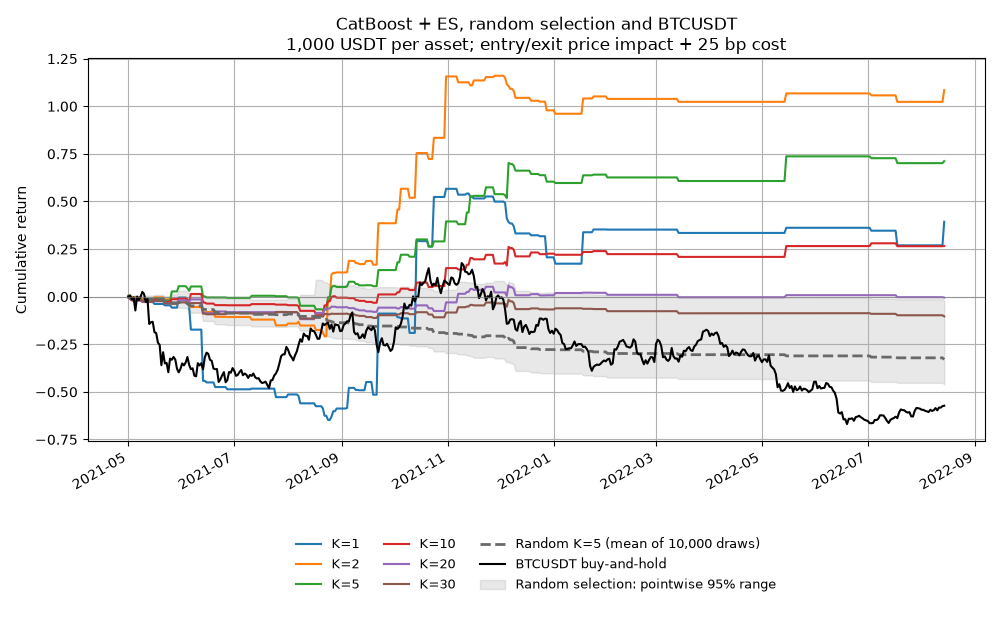

Saved figure: /home/borokoko/dev/pumps_and_dumps/notebooks/analysis_outputs/paper_cohort_473_l2/portfolio_1000usdt_slippage/portfolios_1000usdt_with_slippage.png


In [2]:
from IPython.display import Image
btc = pd.read_csv(REFERENCE / "paper_run/tables/portfolio_returns.csv", index_col=0, parse_dates=True)["BTCUSDT buy-and-hold"]
plot_returns = model_returns.groupby(model_returns.index.normalize()).sum().reindex(btc.index, fill_value=0)
plot_returns.columns = [f"K={k}" for k in SIZES]
random_label = "Random K=5 (mean of 10,000 draws)"
mean_random = random_result["mean_returns"][5]
plot_returns[random_label] = mean_random.groupby(mean_random.index.normalize()).sum().reindex(btc.index, fill_value=0)
plot_returns[btc.name] = btc
band = random_result["paths"].query("k == 5").set_index("time")
figure_path = OUTPUT / "portfolios_1000usdt_with_slippage.png"
fig = plot_equity_curves(
    plot_returns,
    title="CatBoost + ES, random selection and BTCUSDT\n1,000 USDT per asset; entry/exit price impact + 25 bp cost",
    save_path=str(figure_path), baseline_cols=[btc.name], random_col=random_label, random_band=band,
)
fig.savefig(OUTPUT / "portfolios_1000usdt_with_slippage.pdf", bbox_inches="tight")
display(Image(filename=str(figure_path)))
plt.close(fig)
plot_returns.to_csv(OUTPUT / "daily_returns.csv")
provenance = {
    "model": primary_model, "selection": "Highest validation Top@k%AUC",
    "prediction_sha256": hashlib.sha256(prediction_path.read_bytes()).hexdigest(),
    "helper_sha256": hashlib.sha256((PROJECT_ROOT / "notebooks/analysis_helpers.ipynb").read_bytes()).hexdigest(),
    "execution": random_result["execution"], "events": int(scores.pump_hash.nunique()),
    "n_random_draws": 10000, "seed": 42, "no_reinvestment": True,
    "k5_matches_recorded_impact_sweep": True,
    "btc_reference": "Continuous buy-and-hold, same calendar; no strategy price-impact charge applied to this market reference",
}
(OUTPUT / "provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Saved figure: {figure_path}")